<a href="https://colab.research.google.com/github/parinthaokar/-Loan-Default-Prediction/blob/main/Niner_Compute_DE_Workshop_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌍 Build Your First Data Pipeline
### Niner Compute · Data Engineering Workshop #1

Tonight you'll pull real data from the **World Bank**, clean it, put it in a database, and answer questions with it.

**That's it. That's data engineering.** 🎉

### How this works
- Click **File → Save a copy in Drive** first.
- Click a gray box and press **Shift + Enter** to run it. Go top to bottom.
- See `____`? Fill it in. The 👉 hint tells you what goes there.
- Red error? Totally normal. Check your blank and run it again. Stuck? Raise your hand 🙋

## Step 0: Setup
Just run this. It loads our tools.

In [1]:
!pip install -q duckdb
import requests, json
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

# A little tracker so you can see your pipeline come together
STEPS = ["Extract", "Transform", "Load", "Analyze"]
def progress(done):
    bar = "  →  ".join(("✅ " if i < done else "⬜ ") + s for i, s in enumerate(STEPS))
    print("\n🚧 Your pipeline:  " + bar)

print("✅ Ready!")
progress(0)

✅ Ready!

🚧 Your pipeline:  ⬜ Extract  →  ⬜ Transform  →  ⬜ Load  →  ⬜ Analyze


## Step 1: Pick your topic 🎯
Change `MY_TOPIC` to something from your major:

| Major | Try |
|---|---|
| Finance / Business | `"inflation"` or `"gdp_growth"` |
| Economics | `"unemployment"` or `"gdp_per_person"` |
| Health / Nursing | `"life_expectancy"` or `"health_spending"` |
| Environment / Engineering | `"renewable_energy"` or `"forest_area"` |
| Education / Social Sciences | `"college_enrollment"` or `"city_population"` |
| CS / Tech | `"internet_users"` |

In [3]:
MY_TOPIC = "inflation"   # 👉 change this to your topic

topics = {
    "inflation":          "FP.CPI.TOTL.ZG",
    "gdp_growth":         "NY.GDP.MKTP.KD.ZG",
    "unemployment":       "SL.UEM.TOTL.ZS",
    "gdp_per_person":     "NY.GDP.PCAP.CD",
    "life_expectancy":    "SP.DYN.LE00.IN",
    "health_spending":    "SH.XPD.CHEX.GD.ZS",
    "renewable_energy":   "EG.FEC.RNEW.ZS",
    "forest_area":        "AG.LND.FRST.ZS",
    "college_enrollment": "SE.TER.ENRR",
    "city_population":    "SP.URB.TOTL.IN.ZS",
    "internet_users":     "IT.NET.USER.ZS",
}
code = topics[MY_TOPIC]
print("Your topic:", MY_TOPIC)

Your topic: inflation


## Step 2: EXTRACT 🥉 (get the data)
We ask the World Bank's **API** for data. An API is like a waiter: you send an order (a web address), and it brings back data.

We save it exactly as it arrived. This raw copy is called **Bronze**.

In [4]:
# 🧩 Word bank: delete · get · print

# Ask the API for your topic, for every country, 2000-2024
url = f"https://api.worldbank.org/v2/country/all/indicator/{code}"
response = requests.get(url, params={"format": "json", "per_page": 20000, "date": "2000:2024"})   # 👉 get data from a URL
raw_data = response.json()[1]

# Ask for every country's region (we need this to clean the data later)
response = requests.get("https://api.worldbank.org/v2/country", params={"format": "json", "per_page": 500})
country_data = response.json()[1]

print(f"📥 Got {len(raw_data)} rows of data!")

📥 Got 6650 rows of data!


<details><summary>💡 <b>Stuck? Click here for the answer</b></summary><br>Blank 1: <code>get</code></details>

😬 **Step 2 gave an error?** No worries. Scroll to the very **bottom**, run the 🛟 **Backup** cell, then come back here and keep going.

In [5]:
# Save the raw data to a file (our Bronze layer)
with open("bronze_data.json", "w") as f:
    json.dump(raw_data, f)

topic_name = raw_data[0]["indicator"]["value"]
print("Topic:", topic_name)
print("\nHere's ONE raw row. Kind of messy, right?\n")
print(json.dumps(raw_data[0], indent=2))
progress(1)

Topic: Inflation, consumer prices (annual %)

Here's ONE raw row. Kind of messy, right?

{
  "indicator": {
    "id": "FP.CPI.TOTL.ZG",
    "value": "Inflation, consumer prices (annual %)"
  },
  "country": {
    "id": "ZH",
    "value": "Africa Eastern and Southern"
  },
  "countryiso3code": "AFE",
  "date": "2024",
  "value": 4.77085731915833,
  "unit": "",
  "obs_status": "",
  "decimal": 1
}

🚧 Your pipeline:  ✅ Extract  →  ⬜ Transform  →  ⬜ Load  →  ⬜ Analyze


> 💡 **What you just did:** pulled live data from an API and saved a raw copy. Data teams call this **ingestion**, and it's step one of every pipeline.

## Step 3: TRANSFORM 🥈 (clean the data)
Raw data is messy. Ours has 3 problems:
1. 🕳️ Some values are **missing**
2. 🔤 Years are stored as **text**, not numbers
3. 🌐 It includes fake "countries" like **"World"** and **"High income"** (these are totals, not real countries)

Let's fix them. Clean data is called **Silver**.

First, we turn the messy data into a neat table:

In [6]:
# Turn the raw data into a table (like a spreadsheet)
rows = []
for item in raw_data:
    rows.append({
        "code":    item["countryiso3code"],
        "country": item["country"]["value"],
        "year":    item["date"],
        "value":   item["value"],
    })
df = pd.DataFrame(rows)

# A second small table: each country's region
regions = pd.DataFrame([{"code": c["id"], "region": c["region"]["value"].strip()} for c in country_data])

df.head()

,code,country,year,value
0,AFE,Africa Eastern and Southern,2024,4.770857
1,AFE,Africa Eastern and Southern,2023,7.399186
2,AFE,Africa Eastern and Southern,2022,10.883478
3,AFE,Africa Eastern and Southern,2021,6.824727
4,AFE,Africa Eastern and Southern,2020,5.191629


In [7]:
before = len(df)

# Problem 1: remove rows with missing values
df = df.dropna()                                   # 👉 pick one: dropna · head · sort_values
after_fix_1 = len(df)

# Problem 2: turn the year into a number
df["year"] = df["year"].astype(int)                # 👉 pick one: int · str · list   (int = whole number)

# Problem 3: add each country's region, then remove the fake countries
df = df.merge(regions, on="code")                  # 👉 pick one: merge · drop · count   (combines two tables)
df = df[df["region"] != "Aggregates"]              # 👉 pick one: Aggregates · Countries · World Bank

print("🧹 DATA CLEANING REPORT")
print(f"   🕳️  Problem 1 fixed: removed {before - after_fix_1:,} rows with missing values")
print(f"   🔤 Problem 2 fixed: years are now numbers")
print(f"   🌐 Problem 3 fixed: removed {after_fix_1 - len(df):,} rows of fake countries")
print(f"\n   {before:,} messy rows  →  {len(df):,} clean rows")
df.head()

🧹 DATA CLEANING REPORT
   🕳️  Problem 1 fixed: removed 922 rows with missing values
   🔤 Problem 2 fixed: years are now numbers
   🌐 Problem 3 fixed: removed 1,200 rows of fake countries

   6,650 messy rows  →  4,528 clean rows


/tmp/ipykernel_3960/2473906046.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["year"] = df["year"].astype(int)                # 👉 pick one: int · str · list   (int = whole number)


,code,country,year,value,region
1100,AFG,Afghanistan,2024,-6.601186,"Middle East, North Africa, Afghanistan & Pakistan"
1101,AFG,Afghanistan,2023,-4.644709,"Middle East, North Africa, Afghanistan & Pakistan"
1102,AFG,Afghanistan,2022,13.712102,"Middle East, North Africa, Afghanistan & Pakistan"
1103,AFG,Afghanistan,2021,5.133203,"Middle East, North Africa, Afghanistan & Pakistan"
1104,AFG,Afghanistan,2020,5.601888,"Middle East, North Africa, Afghanistan & Pakistan"


<details><summary>💡 <b>Stuck? Click here for the answer</b></summary><br>Blank 1: <code>dropna</code><br>Blank 2: <code>int</code><br>Blank 3: <code>merge</code><br>Blank 4: <code>Aggregates</code></details>

In [8]:
# ✅ Double-check our work (real pipelines always test their data)
assert df["value"].notna().all(), "Still have missing values!"
assert "Aggregates" not in df["region"].values, "Still have fake countries!"
print("✅ Data looks clean!")
progress(2)

✅ Data looks clean!

🚧 Your pipeline:  ✅ Extract  →  ✅ Transform  →  ⬜ Load  →  ⬜ Analyze


> 💡 **What you just did:** found and fixed real problems in messy data, then tested your work. This is called **data quality**, and it's most of what data engineers do day to day.

## Step 4: LOAD 🗄️ (put it in a database)
We load our clean table into **DuckDB**, a real database that runs right here. Companies do the same thing with tools like Snowflake.

In [9]:
# 🧩 Word bank: CHART · FILE · TABLE

db = duckdb.connect()
db.execute("CREATE TABLE silver AS SELECT * FROM df")   # 👉 a database stores data in a ____
print(f"✅ Loaded {len(df):,} clean rows into your database!")
progress(3)

✅ Loaded 4,528 clean rows into your database!

🚧 Your pipeline:  ✅ Extract  →  ✅ Transform  →  ✅ Load  →  ⬜ Analyze


<details><summary>💡 <b>Stuck? Click here for the answer</b></summary><br>Blank 1: <code>TABLE</code></details>

## Step 5: ANALYZE 🥇 (ask questions)
Now we ask the database questions using **SQL**. It reads almost like English:

`SELECT` *what you want* · `FROM` *which table* · `WHERE` *a filter* · `ORDER BY` *how to sort*

We'll compare countries in **2022** (the most recent year almost every country has reported). Summary data like this is called **Gold**.

In [10]:
# 🧩 Word bank: LIMIT · SELECT · WHERE

# The top 10 countries in 2022
db.sql("""
    SELECT country, value
    FROM silver
    WHERE year = 2022
    ORDER BY value DESC
    LIMIT 10
""")
# 👉 the keyword that keeps only the first 10 rows

┌────────────────────┬──────────────────┐
│      country       │      value       │
│      varchar       │      double      │
├────────────────────┼──────────────────┤
│ Lebanon            │ 171.205491336641 │
│ Sudan              │  138.80846024176 │
│ Zimbabwe           │ 104.705170628667 │
│ Argentina          │  72.430757531824 │
│ Turkiye            │ 72.3088300496956 │
│ Suriname           │  52.446027276241 │
│ Sri Lanka          │ 49.7211021114327 │
│ Iran, Islamic Rep. │ 43.4884641742178 │
│ Haiti              │   33.98393194707 │
│ Ethiopia           │ 33.8898797100898 │
├────────────────────┴──────────────────┤
│ 10 rows                     2 columns │
└───────────────────────────────────────┘

<details><summary>💡 <b>Stuck? Click here for the answer</b></summary><br>Blank 1: <code>LIMIT</code></details>

In [11]:
# 🧩 Word bank: ASC · DESC

# The bottom 10 countries in 2022
db.sql("""
    SELECT country, value
    FROM silver
    WHERE year = 2022
    ORDER BY value ASC
    LIMIT 10
""")
# 👉 ASC = smallest first, DESC = biggest first

┌──────────────────────┬───────────────────┐
│       country        │       value       │
│       varchar        │      double       │
├──────────────────────┼───────────────────┤
│ South Sudan          │ -6.68732094212667 │
│ Macao SAR, China     │  1.04502802369953 │
│ Benin                │  1.35077863583527 │
│ Bolivia              │  1.74632872945968 │
│ Hong Kong SAR, China │  1.88136707196852 │
│ China                │   1.9735755573905 │
│ Maldives             │  2.33054046477249 │
│ Japan                │  2.49770278172254 │
│ Oman                 │  2.50614250614249 │
│ Saudi Arabia         │   2.5441644569453 │
├──────────────────────┴───────────────────┤
│ 10 rows                        2 columns │
└──────────────────────────────────────────┘

<details><summary>💡 <b>Stuck? Click here for the answer</b></summary><br>Blank 1: <code>ASC</code></details>

In [12]:
# 🧩 Word bank: country · region · value

# The average for each region
db.sql("""
    SELECT region, ROUND(AVG(value), 1) AS average
    FROM silver
    WHERE year = 2022
    GROUP BY region
    ORDER BY average DESC
""")
# 👉 GROUP BY combines rows: one result per ____

┌───────────────────────────────────────────────────┬─────────┐
│                      region                       │ average │
│                      varchar                      │ double  │
├───────────────────────────────────────────────────┼─────────┤
│ Middle East, North Africa, Afghanistan & Pakistan │    16.3 │
│ Sub-Saharan Africa                                │    15.7 │
│ South Asia                                        │    13.3 │
│ Europe & Central Asia                             │    12.6 │
│ Latin America & Caribbean                         │    11.7 │
│ North America                                     │     7.4 │
│ East Asia & Pacific                               │     6.6 │
└───────────────────────────────────────────────────┴─────────┘

<details><summary>💡 <b>Stuck? Click here for the answer</b></summary><br>Blank 1: <code>region</code></details>

In [13]:
# ✍️ YOUR question! Change the country name, or write your own SQL.
db.sql("""
    SELECT year, value
    FROM silver
    WHERE country = 'United States'
    ORDER BY year
""")

┌───────┬────────────────────┐
│ year  │       value        │
│ int64 │       double       │
├───────┼────────────────────┤
│  2000 │   3.37685727149929 │
│  2001 │   2.82617111885407 │
│  2002 │   1.58603162650601 │
│  2003 │   2.27009497336114 │
│  2004 │   2.67723669309171 │
│  2005 │    3.3927468454955 │
│  2006 │   3.22594410070404 │
│  2007 │   2.85267248150138 │
│  2008 │   3.83910029665099 │
│  2009 │ -0.355546266299747 │
│    ·  │           ·        │
│    ·  │           ·        │
│    ·  │           ·        │
│  2015 │   0.11862713555245 │
│  2016 │   1.26158320570535 │
│  2017 │   2.13011000365961 │
│  2018 │   2.44258329692816 │
│  2019 │    1.8122100752602 │
│  2020 │   1.23358439630629 │
│  2021 │   4.69785886363742 │
│  2022 │   8.00279982052121 │
│  2023 │   4.11633838374487 │
│  2024 │   2.94952520485207 │
├───────┴────────────────────┤
│     25 rows (20 shown)     │
└────────────────────────────┘

> 💡 **What you just did:** answered real questions with SQL, the #1 skill on data job postings. Turning clean data into answers is the **Gold** layer.

## Step 6: Make a chart 📈
Pick a few countries to compare. Add your home country!

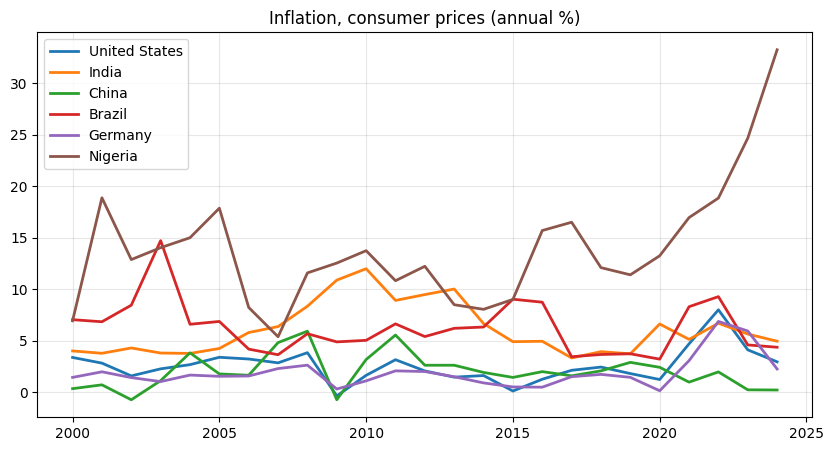


🚧 Your pipeline:  ✅ Extract  →  ✅ Transform  →  ✅ Load  →  ✅ Analyze

🎉 PIPELINE COMPLETE!


In [14]:
my_countries = ["United States", "India", "China", "Brazil", "Germany", "Nigeria"]   # 👉 change these!

plt.figure(figsize=(10, 5))
for name in my_countries:
    data = df[df["country"] == name].sort_values("year")
    plt.plot(data["year"], data["value"], label=name, linewidth=2)

plt.title(topic_name)
plt.legend()
plt.grid(alpha=0.3)
plt.show()
progress(4)
print("\n🎉 PIPELINE COMPLETE!")

## Step 7: Make it a resume project 💼
1. Go to [github.com/new](https://github.com/new), name it `world-data-pipeline`, check **Add a README**, and click **Create**.
2. Here in Colab: **File → Save a copy in GitHub** → pick that repo.
3. Run the cell below for your resume bullet. It uses **your** real numbers.

In [ ]:
n_countries = df["country"].nunique()
n_rows = len(df)

print("🏆 YOUR PIPELINE REPORT CARD")
print("=" * 45)
print(f"📥 Extracted   {len(raw_data):,} raw records from a live API")
print(f"🧹 Cleaned     fixed 3 data problems, removed {before - n_rows:,} bad rows")
print(f"🗄️  Loaded      {n_rows:,} clean records into a SQL database")
print(f"🌍 Analyzed    {n_countries} countries, {df['year'].min()}–{df['year'].max()}")
print(f"📊 Answered    4 questions with SQL + built a chart")
print("=" * 45)
print("🛠️  Skills used: Python · pandas · SQL · REST APIs · DuckDB · Data Quality\n")

print("📄 Your resume bullet:\n")
print(f"• Built a data pipeline in Python that pulls World Bank data on {topic_name.lower()} "
      f"for {n_countries} countries from an API, cleans {n_rows:,} records with pandas, "
      f"and loads them into a DuckDB database for SQL analysis.")

## 🎉 You built a data pipeline!
**Get data → clean it → store it → ask questions.** Same steps real data engineers use every day.

**Make it yours this week:** try a second topic, write your own SQL question, and be ready to explain each step.

**Next time:** we make this run by itself on a schedule. 👀
Join our Discord and follow **@ninercompute**!

---

## 🛟 Backup (ONLY if Step 2 failed)
Run this, then scroll back up to the cell after Step 2 and keep going. It makes practice data in the same format.

In [ ]:
import random
random.seed(1)
countries = [("USA","United States","North America"), ("CAN","Canada","North America"),
             ("MEX","Mexico","Latin America & Caribbean"), ("BRA","Brazil","Latin America & Caribbean"),
             ("GBR","United Kingdom","Europe & Central Asia"), ("DEU","Germany","Europe & Central Asia"),
             ("IND","India","South Asia"), ("CHN","China","East Asia & Pacific"),
             ("JPN","Japan","East Asia & Pacific"), ("NGA","Nigeria","Sub-Saharan Africa"),
             ("ZAF","South Africa","Sub-Saharan Africa"), ("EGY","Egypt, Arab Rep.","Middle East & North Africa"),
             ("WLD","World","Aggregates")]
country_data = [{"id": c, "region": {"value": r}} for c, n, r in countries]
raw_data = []
for c, n, r in countries:
    level = random.uniform(2, 10)
    for year in range(2000, 2025):
        level = max(0.1, level + random.uniform(-1, 1))
        raw_data.append({"indicator": {"value": f"{MY_TOPIC} (practice data)"},
                         "country": {"value": n}, "countryiso3code": c, "date": str(year),
                         "value": None if random.random() < 0.05 else round(level, 2)})
print("✅ Backup data loaded. Scroll back up and keep going!")